In [54]:
from datascience import *
import numpy as np
import pandas as pd
import statistics as stats
import scipy.stats as sci 
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plots
import math
plots.style.use('fivethirtyeight')
import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

# Week 6 - Notebook 2: 5.2

## 5.2 Any Normal Distribution

Since the data does not fit the standard normal distribution with mean = 0 and standard deviation = 1, we will standardize the data before analyzing.  
To standardize data, we convert the data's x-value to a z-score, then evaluate on a standard normal curve. 

### Formula
$z = \dfrac{x-\mu}{\sigma} = \dfrac{\text{data value} - \text{mean}}{\text{standard deviation}}$

### Solution Notation
$P(x...) = P(z...) = $

For this class, when calculating probabilities, you need to convert first to $z$ then use the same formulas for the standard normal calculations.
|You want|Function|
|--------|--------|
|P(Z ≤ z)| `sci.norm.cdf(z)`|
|P(Z ≥ z)|`sci.norm.sf(z)`|
|P(a ≤ Z ≤ b)|`sci.norm.cdf(b) - sci.norm.cdf(a)`
    
You can use this command for checking your answers: `sci.norm.cdf(x, loc=mu, scale=sigma)`  
where loc = the mean of the distribution, and scale = the standard deviation of the distribution.

Copy in the function for shading the curve from the previous Notebook and edit it so it fits with a non-standard normal distribution.

In [35]:
def plot_normal_shaded(mu, sigma, lower=None, upper=None):
    """
    Plots a normal distribution curve with a shaded probability region.
    
    Parameters:
        mu, sigma : mean and standard deviation of the distribution
        lower, upper : bounds of the shaded region.
                       - lower=None -> shades from left tail up to `upper` (P(X < upper))
                       - upper=None -> shades from `lower` to right tail (P(X > lower))
                       - both given -> shades between them (P(lower < X < upper))
    """
    x_vals = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
    y_vals = sci.norm.pdf(x_vals, loc=mu, scale=sigma)

    fig, ax = plots.subplots(figsize=(8, 5))
    ax.plot(x_vals, y_vals, color='black', linewidth=1.5)

    # Determine shading range and compute probability
    if lower is None:
        x1 = x2 = upper
        shade_x = np.linspace(mu - 4*sigma, upper, 500)
        label = f"P(X < {upper:.2f})"
    elif upper is None:
        x1 = x2 = lower
        shade_x = np.linspace(lower, mu + 4*sigma, 500)
        label = f"P(X > {lower:.2f})"
    else:
        x1 = lower
        x2 = upper
        shade_x = np.linspace(lower, upper, 500)
        label = f"P({lower:.2f} < X < {upper:.2f})"

    shade_y = sci.norm.pdf(shade_x, loc=mu, scale=sigma)
    ax.fill_between(shade_x, shade_y, color='steelblue', alpha=0.5)
    ax.axvline(x1, color='darkred', linestyle='--', linewidth=1)
    ax.axvline(x2, color='darkred', linestyle='--', linewidth=1)
    ax.set_title(label)
    ax.set_xlabel("X")
    ax.set_ylabel("Probability Density")
    plots.show()


***QUESTION: How would you create a function that will calculate a z-score?***

In [14]:
def z_score(x, mu = 0, sigma = 1):
    z = (x - mu)/sigma
    return print("Z-score = ", z)


**EXAMPLE:**
1. 	In a certain 5th grade class, the most recent history test score average was 50% with a standard deviation of 10%. The distribution of the scores was approximately normal. Find the probability a randomly selected student would have done the following:  
    a. What is μ and σ?  
    b. Find $P(x<43)$



In [21]:
z_score(43,50,10) 

Z-score =  -0.7


In [26]:
p43 = sci.norm.cdf(-0.7)
print("P(X < 43)= P(Z < -0.7)", p43)

P(X < 43)= P(Z < -0.7) 0.241963652223


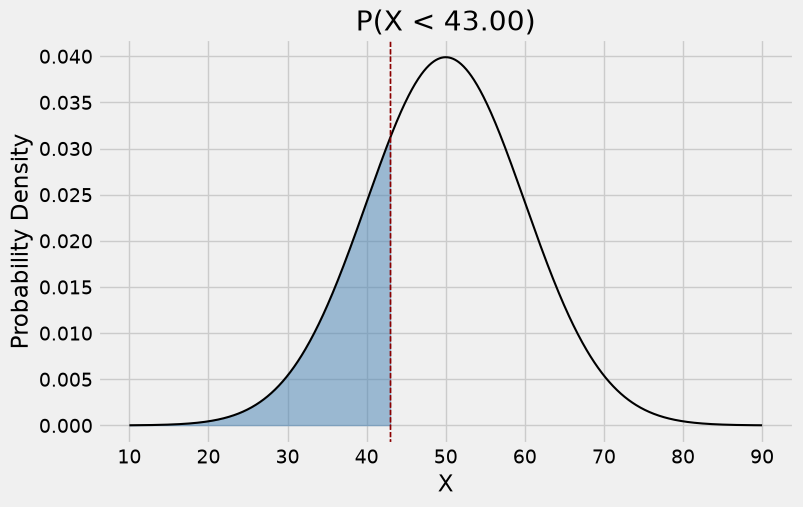

In [36]:
plot_normal_shaded(50, 10, upper = 43)

c. Find $P(x>65)$  
   

In [28]:
z_score(65,50,10) 

Z-score =  1.5


In [29]:
p65 = sci.norm.cdf(1.5)
print("P(X < 65)= P(Z < 1.5)", p65)

P(X < 65)= P(Z < 1.5) 0.933192798731


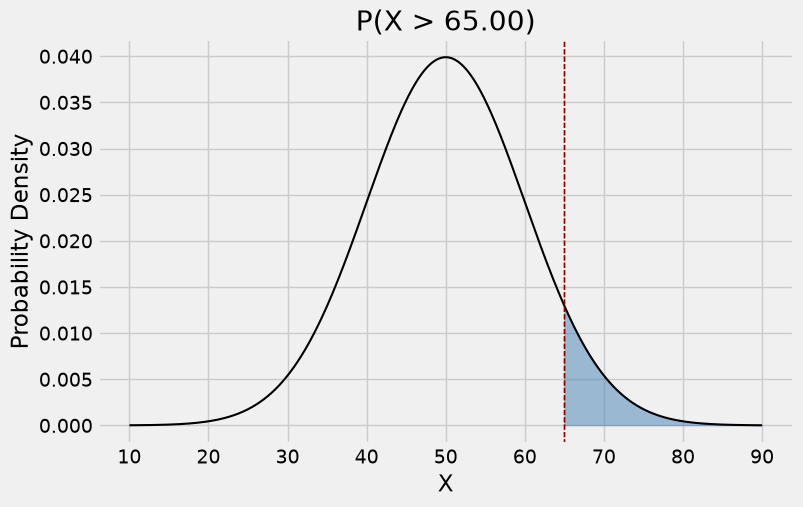

In [37]:
plot_normal_shaded(50, 10, lower = 65)

d. Find $P(32<x<52)$

In [31]:
z_score(32,50,10) 

Z-score =  -1.8


In [32]:
z_score(52,50,10) 

Z-score =  0.2


In [33]:
pbetween = sci.norm.cdf(0.2) - sci.norm.cdf(-1.8)
print("P(32 < X  < 52)= P(-1.8 < Z  < 0.2)= ",pbetween)

P(32 < X  < 52)= P(-1.8 < Z  < 0.2)=  0.543329390326


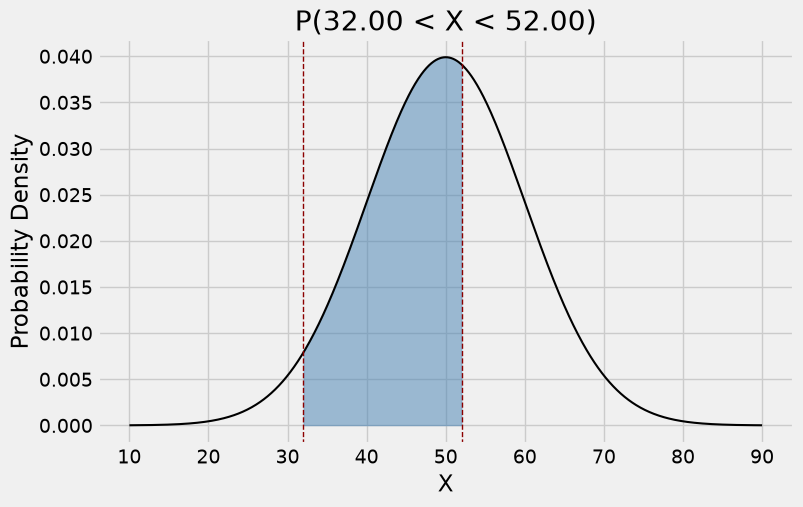

In [38]:
plot_normal_shaded(50, 10, lower = 32, upper = 52)

### Non- Standard Inverse Problems

|You want| Direct scipy approach|
|--------|---------------------|
|x such that P(X ≤ x) = p|sci.norm.ppf(p, loc=mu, scale=sigma)|
|x such that P(X ≥ x) = p|sci.norm.isf(p, loc=mu, scale=sigma)|
|lower & upper such that P(lower < X < upper) = p |sci.norm.ppf(tail, loc=mu, scale=sigma) and sci.norm.ppf(1-tail, loc=mu, scale=sigma)|

where loc = the mean of the distribution, and scale = the standard deviation of the distribution.


**EXAMPLE**  
2. Find the variable value for the following distributions.  
    a. μ=50,σ=10, and the score was in the 79th percentile



In [40]:
a = sci.norm.ppf(.79, loc=50, scale=10)
a

58.064212470182405

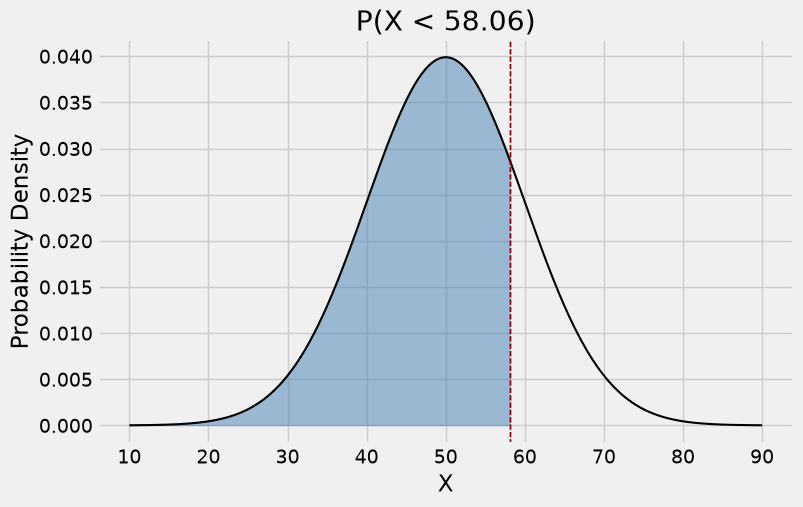

In [41]:
plot_normal_shaded(50, 10, upper = a)

b. μ=72, σ=4, and the score was in the top 0.20. 


In [42]:
b = sci.norm.isf(0.20, loc=72, scale=4)
b

75.366484934291663

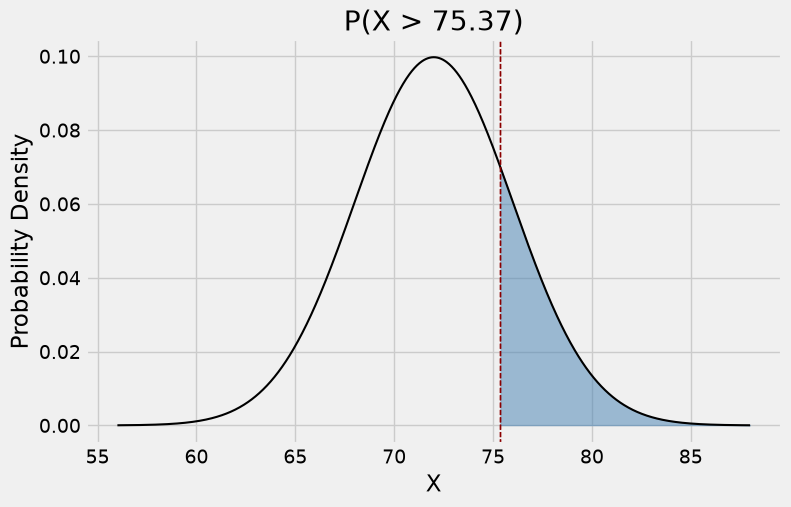

In [43]:
plot_normal_shaded(72, 4, lower = b)

c. μ=40, σ=8, the score was in the middle 40\%.  
*Note: First figure out the lower area and upper area that remain.*

In [44]:
remain = 100-40
remain

60

In [45]:
sides = 60/2
sides

30.0

In [46]:
lowerarea = .30
upperarea = 0.40+0.30
lowerarea, upperarea

(0.3, 0.7)

In [50]:
lowx = sci.norm.ppf(0.3, loc=40, scale=8)
highx = sci.norm.ppf(0.7, loc=40, scale=8)
lowx, highx

(35.804795898335669, 44.195204101664324)

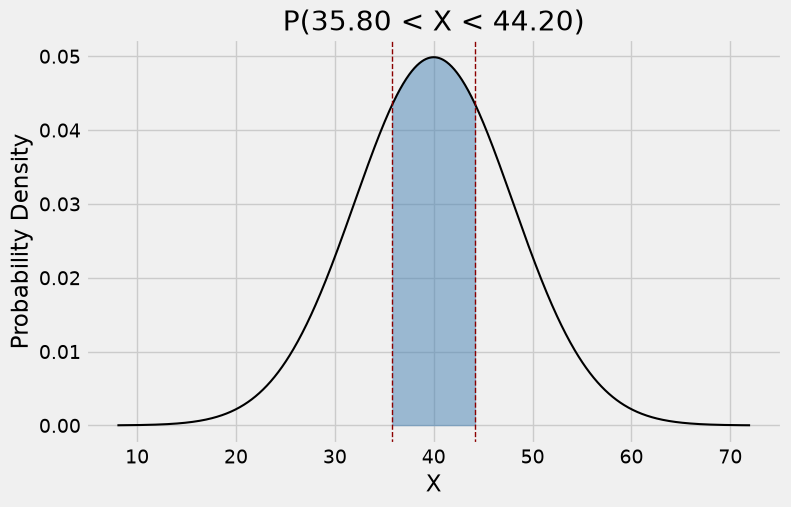

In [51]:
plot_normal_shaded(40, 8, lower = lowx, upper = highx)

***QUESTIONS***  
Our goal is to see how a binomial distribution can sometimes be approximately normal.

1.	In Oct 2022 there were 48 Democrats in the U.S. Senate. That means 48\% of the Senate was Democrat. Suppose we randomly sample 10 Senators and record if they are a Democrat or not.  
    a.	This is a binomial experiment. What is n and what is p?  
    b.	Use formulas from section 4.2 to create a probabilitiy distribution table with the probabilities for all the different possible x-values for this experiment. Round to two decimal places. Then create a histogram representing the table.  
    c.	What is the shape of the histogram you created?  
    d.	What is the probability that at most 4 Democrats were in the sample? Round to 4 decimal places.  
    e.	What is the probability that between 6 and 9 (inclusive) Democrats are in the sample? Round to 4 decimal places.  




In [52]:
dem0 = sci.binom.pmf(0, 10, 0.48)
dem1 = sci.binom.pmf(1, 10, 0.48)
dem2 = sci.binom.pmf(2, 10, 0.48)
dem3 = sci.binom.pmf(3, 10, 0.48)
dem4 = sci.binom.pmf(4, 10, 0.48)
dem5 = sci.binom.pmf(5, 10, 0.48)
dem6 = sci.binom.pmf(6, 10, 0.48)
dem7 = sci.binom.pmf(7, 10, 0.48)
dem8 = sci.binom.pmf(8, 10, 0.48)
dem9 = sci.binom.pmf(9, 10, 0.48)
dem10 = sci.binom.pmf(10, 10, 0.48)


In [55]:
# Values and their probabilities
data = {
    'X': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'P(X)': [dem0, dem1, dem2, dem3, dem4, dem5, dem6, dem7, dem8, dem9, dem10]
}

df = pd.DataFrame(data)
print(df)
print("Sum of probabilities:", df['P(X)'].sum())  # should be 1.0

     X      P(X)
0    0  0.001446
1    1  0.013344
2    2  0.055427
3    3  0.136436
4    4  0.220396
5    5  0.244131
6    6  0.187793
7    7  0.099056
8    8  0.034289
9    9  0.007034
10  10  0.000649
Sum of probabilities: 1.0


In [59]:
atmost4 = sci.binom.cdf(4, 10, 0.48)
print("P(x<=4) = ", atmost4)

P(x<=4) =  0.427048256121


In [60]:
between = sci.binom.cdf(9, 10, 0.48) - sci.binom.cdf(6-1, 10, 0.48)
print("P(6 <= X <= 9)=",between)

P(6 <= X <= 9)= 0.32817120333


***QUESTIONS***  
Because the binomial distribution is approximately normal, we should be able to use `sci.norm.cdf(x)` to find the same probabilities from the previous questions.
 
1. The formulas for the mean and standard deviation of a binomial distribution are $\mu=np$ and $\sigma=\sqrt(np(1-p))$. Find $\mu$ and $\sigma$ for this distribution. Use n and p from the previous page. Round to two decimal places.  
2. We will approximate the probability that at most 4 Democrats were in the sample by using `sci.norm.cdf(x)` and finding $P(x<4.5)$.  Since we need to include the probability of 4, we are choosing an x above 4. Find $P(x<4.5)$ and show a graph of the area we’re finding. Compare your answer to the answer of \#1d.  
3. 	We will approximate the probability that between 6 and 9 (inclusive) Democrats were in the sample by using `sci.norm.cdf(x)` and finding $P(5.5< x<9.5)$.  
    a. Why does it make sense that we’re drawing the lines at 5.5 and 9.5? 
    b. Find $P(5.5< x<9.5)$ and show a graph of the area we’re finding. Compare your answer to \#1e.


In [66]:
n = 10
p = 0.48
mu = n*p
sigma = np.sqrt(n*p*(1-p))
mu, sigma

(4.8, 1.5798734126505198)

In [67]:
z_score(4.5, mu, sigma)

Z-score =  -0.189888631328


In [93]:
less4 = sci.norm.cdf(-0.189889)
print("P(x<=4) = ",less4)

P(x<=4) =  0.424698056187


In [91]:
atmost4

0.42704825612080516

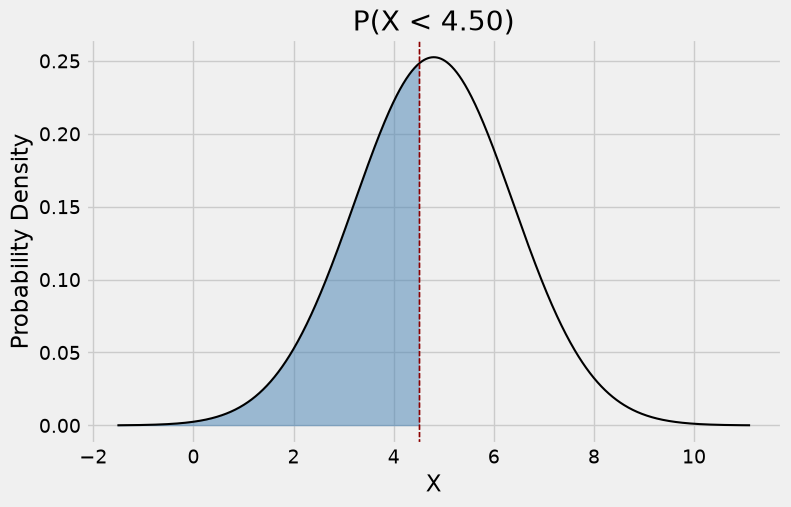

In [73]:
plot_normal_shaded(mu, sigma, upper = 4.5)

In [86]:
z_score(5.5, mu, sigma)

Z-score =  0.443073473099


In [87]:
z_score(9.5, mu, sigma)

Z-score =  2.97492189081


In [88]:
zlower = 0.44307
zupper = 2.9749
zupper, zlower

(2.9749, 0.44307)

In [89]:
between2 = sci.norm.cdf(zupper) - sci.norm.cdf(zlower)
print("P(6 <= X <= 9)=",between)

P(6 <= X <= 9)= 0.32817120333


In [92]:
between

0.3281712033300479

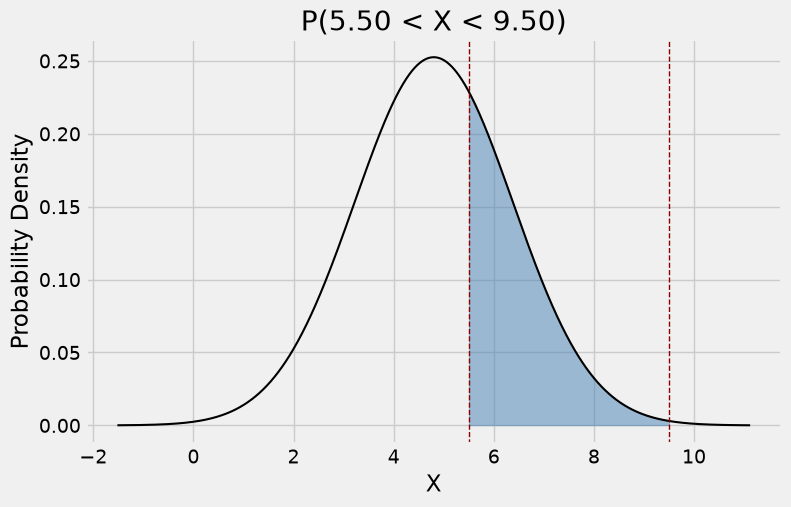

In [90]:
plot_normal_shaded(mu, sigma, lower = 5.5, upper = 9.5)